In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    brier_score_loss,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.calibration import CalibrationDisplay

In [8]:
df = pd.read_csv("../data/raw/flights.csv")
df = df.dropna(subset=["arr_delay"]).copy()

df["delayed"] = (df["arr_delay"] >= 15).astype(int)

df["scheduled_datetime"] = (
    pd.to_datetime(df["time_hour"]) +
    pd.to_timedelta(df["minute"], unit="m")
)

df["day_of_week"] = df["scheduled_datetime"].dt.dayofweek
df["day_of_year"] = df["scheduled_datetime"].dt.dayofyear

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)
df["day_of_year_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)
df["day_of_year_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

feature_cols = [
    "month", "day", "hour", "minute",
    "day_of_week", "day_of_year",
    "hour_sin", "hour_cos",
    "dow_sin", "dow_cos",
    "day_of_year_sin", "day_of_year_cos",
    "distance", "carrier", "origin", "dest"
]

df = df.sort_values("scheduled_datetime").reset_index(drop=True)

X = df[feature_cols]
y = df["delayed"]

train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.85)

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Test samples:", len(X_test))
print("Test delay rate:", round(y_test.mean() * 100, 2), "%")

Test samples: 49102
Test delay rate: 26.69 %


/var/folders/42/1195kj1s5cnfdl1h85ykvth40000gn/T/ipykernel_63302/3267508670.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["scheduled_datetime"].dt.dayofweek
/var/folders/42/1195kj1s5cnfdl1h85ykvth40000gn/T/ipykernel_63302/3267508670.py:12: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["scheduled_datetime"].dt.dayofyear


In [9]:
logistic_bundle = joblib.load(
    "../models/logistic_regression_baseline.joblib"
)

xgb_bundle = joblib.load(
    "../models/xgboost_model.joblib"
)

logistic_model = logistic_bundle["model"]
xgb_model = xgb_bundle["model"]

logistic_threshold = logistic_bundle["threshold"]

# Use the threshold selected for XGBoost during validation.
xgb_threshold = 0.3

logistic_probs = logistic_model.predict_proba(X_test)[:, 1]
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

print("Both models loaded successfully.")
print("Logistic Regression threshold:", round(logistic_threshold, 4))
print("XGBoost threshold:", xgb_threshold)

Both models loaded successfully.
Logistic Regression threshold: 0.7223
XGBoost threshold: 0.3


In [10]:
models = {
    "Logistic Regression": (logistic_probs, logistic_threshold),
    "XGBoost": (xgb_probs, xgb_threshold)
}

results = []

for name, (probs, threshold) in models.items():
    preds = (probs >= threshold).astype(int)

    results.append({
        "Model": name,
        "PR AUC": average_precision_score(y_test, probs),
        "ROC AUC": roc_auc_score(y_test, probs),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1 Score": f1_score(y_test, preds, zero_division=0),
        "Accuracy": accuracy_score(y_test, preds),
        "Brier Score": brier_score_loss(y_test, probs)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,PR AUC,ROC AUC,Precision,Recall,F1 Score,Accuracy,Brier Score
Model,,,,,,,
Logistic Regression,0.3084,0.5682,0.0000,0.0000,0.000,0.7331,0.2092
XGBoost,0.3338,0.5985,0.3364,0.5054,0.404,0.6019,0.2091


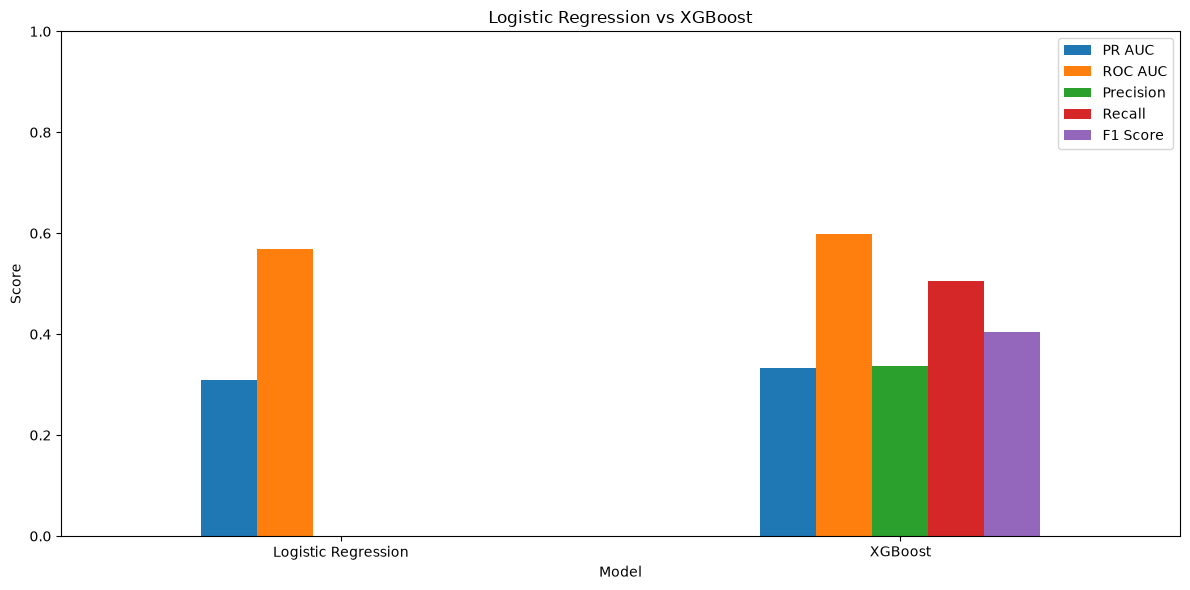

In [11]:
results_df[
    ["PR AUC", "ROC AUC", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Logistic Regression vs XGBoost")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

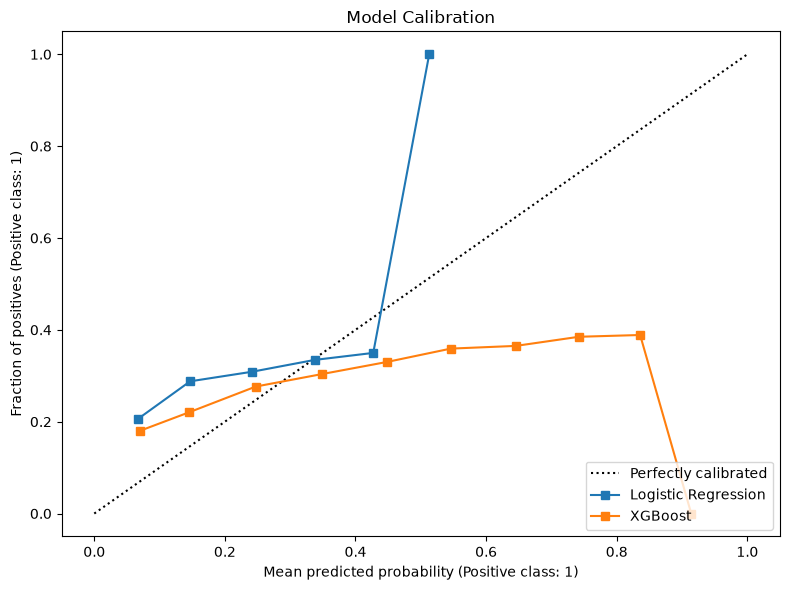

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_test,
    logistic_probs,
    n_bins=10,
    name="Logistic Regression",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_test,
    xgb_probs,
    n_bins=10,
    name="XGBoost",
    ax=ax
)

ax.set_title("Model Calibration")
plt.tight_layout()
plt.show()